# Intro

* The rest of the transformer block in which the attention equation is embedded
* The idea of the feedforward expansion-contraction sublayer that follows attention
* How dimension expansion can help models extract features and linearly separate categories

Transformer Block has 2 parts

1. Attention Sublayer
2. MLP Sublayer

MLP takes Attention Sublayer expand it 4 times, use GELU layer and then 4 times contract to get residual stream. The idea is to add new dimensionality to make easier data classification.

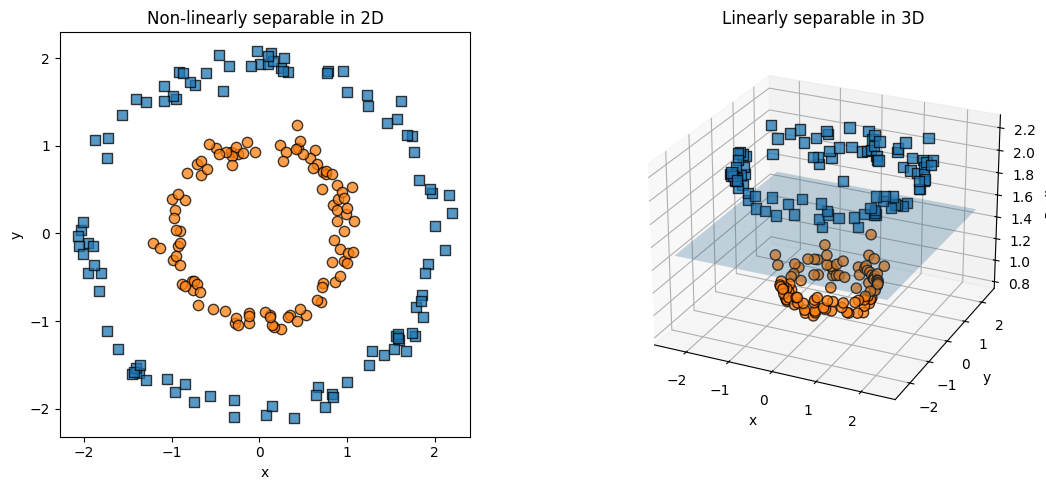

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# -----------------------
# Generate two noisy rings
# -----------------------
n = 100

theta_inner = np.random.uniform(0, 2*np.pi, n)
theta_outer = np.random.uniform(0, 2*np.pi, n)

r_inner = np.random.normal(1.0, 0.08, n)
r_outer = np.random.normal(2.0, 0.10, n)

x_inner = r_inner * np.cos(theta_inner)
y_inner = r_inner * np.sin(theta_inner)

x_outer = r_outer * np.cos(theta_outer)
y_outer = r_outer * np.sin(theta_outer)

# Third dimension: radius / nonlinear feature
z_inner = np.sqrt(x_inner**2 + y_inner**2)
z_outer = np.sqrt(x_outer**2 + y_outer**2)

# -----------------------
# Plot
# -----------------------
fig = plt.figure(figsize=(12, 5))

# 2D plot
ax1 = fig.add_subplot(1, 2, 1)

ax1.scatter(
    x_outer, y_outer,
    marker="s",
    s=55,
    alpha=0.75,
    edgecolor="black",
    label="Outer class"
)

ax1.scatter(
    x_inner, y_inner,
    marker="o",
    s=55,
    alpha=0.75,
    edgecolor="black",
    label="Inner class"
)

ax1.set_title("Non-linearly separable in 2D")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_aspect("equal")


# 3D plot
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

ax2.scatter(
    x_outer, y_outer, z_outer,
    marker="s",
    s=55,
    alpha=0.75,
    edgecolor="black"
)

ax2.scatter(
    x_inner, y_inner, z_inner,
    marker="o",
    s=55,
    alpha=0.75,
    edgecolor="black"
)

# optional separating plane between classes
xx, yy = np.meshgrid(
    np.linspace(-2.4, 2.4, 20),
    np.linspace(-2.4, 2.4, 20)
)
zz = np.ones_like(xx) * 1.5

ax2.plot_surface(xx, yy, zz, alpha=0.25)

ax2.set_title("Linearly separable in 3D")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("Radius")

ax2.view_init(elev=25, azim=-65)

plt.tight_layout()
plt.show()

In above example by adding 1 dimension we can simply divide datapoints by color.

Attention:

* Integrate relevant context from other tokens. Boost activation of relevant past tokens to reactivate in the future.
* Q "asks" for relevant toknes; K "advertises" their content; V has the context details.

MLP:

* Expand dimensionality to have a richer space for complex feature transformation and (linear) decision boundaries
* All tokens are processed simultaneously; there is no cross-talk or temporal causality


# Code

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D # for #d plotting

import torch
import torch.nn as nn
import torch.nn.functional as F

# vector plots
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

Demo of linear separation after dimensionality expansion

In [4]:
# data hyperparameters
seq_len = 8

# model hyperparameters
embed_dim = 128

# training hyperparameters
batch_size = 5

One attention head

In [5]:
class OneAttentionHead(nn.Module):
  def __init__(self, embed_dim):
    super().__init__()

    # create the k/q/v matrices
    self.key    = nn.Linear(embed_dim, embed_dim, bias = False)
    self.query  = nn.Linear(embed_dim, embed_dim, bias = False)
    self.value  = nn.Linear(embed_dim, embed_dim, bias = False)
    self.W0     = nn.Linear(embed_dim, embed_dim, bias = False)

  def forward(self, x):

    # run the tokens through attention
    k = self.key(x)
    q = self.query(x)
    v = self.value(x)
    y = F.scaled_dot_product_attention(q,k,v,is_causal = True) # is_causal - time causal mask is included
    y = self.W0(y) # linear weightings post-attention

    return y

In [6]:
# explore the attention head
one_head = OneAttentionHead(embed_dim)

print(one_head)

# run some fake data through
token_embeds = torch.randn(batch_size, seq_len, embed_dim)
out = one_head(token_embeds)
print(f'\nOutput ({out.shape}): \n\n{out}')

OneAttentionHead(
  (key): Linear(in_features=128, out_features=128, bias=False)
  (query): Linear(in_features=128, out_features=128, bias=False)
  (value): Linear(in_features=128, out_features=128, bias=False)
  (W0): Linear(in_features=128, out_features=128, bias=False)
)

Output (torch.Size([5, 8, 128])): 

tensor([[[ 0.1336, -0.0216,  0.2731,  ...,  0.5185, -0.1215,  0.0724],
         [ 0.0109,  0.1108,  0.1060,  ...,  0.2543, -0.1260,  0.0337],
         [ 0.1038, -0.1561,  0.0365,  ...,  0.1667, -0.2770,  0.1100],
         ...,
         [-0.0423,  0.0555, -0.0435,  ...,  0.0434, -0.1166,  0.0112],
         [-0.1796, -0.0212, -0.0475,  ..., -0.0325, -0.0991,  0.0306],
         [-0.1969,  0.0222,  0.0266,  ...,  0.0340, -0.1654,  0.0078]],

        [[ 0.3408, -0.2958, -0.1904,  ...,  0.1503,  0.0715,  0.5194],
         [ 0.2488, -0.1268, -0.2324,  ..., -0.1887,  0.0907,  0.2240],
         [ 0.2113, -0.1691,  0.1237,  ..., -0.1756,  0.0247,  0.0378],
         ...,
         [ 0.0114, 

Transformer block

In [7]:
class TransformerBlock(nn.Module):
  def __init__(self, embed_dim):
    super().__init__()

    # attention sublayer
    self.layer_norm_attn = nn.LayerNorm(embed_dim)
    self.attn = OneAttentionHead(embed_dim)

    # feedforward (MLP) sublayer
    self.layer_norm_mlp = nn.LayerNorm(embed_dim)
    self.W1             = nn.Linear(embed_dim, 4*embed_dim) # 4x expansion
    self.gelu           = nn.GELU()
    self.W2             = nn.Linear(4*embed_dim, embed_dim)

  def forward(self, x):
    ## --- attention sublayer --- ##

    residual = x

    # layernorm -> attention
    h        = self.layer_norm_attn(x)
    attn_out = self.attn(h)

    # combine pre-attention copy + attention adjustments
    x        = residual + attn_out

    ## --- MLP sublayer --- ###
    # copy of pre-MLP data
    residual2 = x

    # layernorm before MLP
    h2        = self.layer_norm_mlp(x)

    # expansion-nonlinearity-contraction
    mlp_out   = self.W2(self.gelu(self.W1(h2)))

    # combine pre-MLP copy + MLP-adjustment
    y         = residual2 + mlp_out

    ## ---------------------------- ##

    return y

In [9]:
# create and explore an instance
transblock = TransformerBlock(embed_dim)
print(transblock)

TransformerBlock(
  (layer_norm_attn): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (attn): OneAttentionHead(
    (key): Linear(in_features=128, out_features=128, bias=False)
    (query): Linear(in_features=128, out_features=128, bias=False)
    (value): Linear(in_features=128, out_features=128, bias=False)
    (W0): Linear(in_features=128, out_features=128, bias=False)
  )
  (layer_norm_mlp): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (W1): Linear(in_features=128, out_features=512, bias=True)
  (gelu): GELU(approximate='none')
  (W2): Linear(in_features=512, out_features=128, bias=True)
)


In [10]:
# again, pushing data through
out = transblock(token_embeds)
print(f'\nOutput ({out.shape}): \n{out}')


Output (torch.Size([5, 8, 128])): 
tensor([[[ 1.5430, -1.0533,  0.2244,  ..., -0.3362,  0.5374, -0.9607],
         [ 0.5106,  1.3676, -1.1477,  ...,  0.0133, -0.4601, -1.8134],
         [-0.2148, -0.7544,  0.1397,  ..., -0.9857,  0.5400, -2.2804],
         ...,
         [ 3.0551, -1.7438, -0.7079,  ..., -1.0567,  0.9022,  1.2330],
         [-1.4351,  1.0600,  1.9171,  ...,  1.3343,  0.2386, -2.2665],
         [ 1.8349,  0.6077, -0.3093,  ...,  1.4448,  1.7382,  0.0906]],

        [[-0.5315,  0.6792, -0.4037,  ..., -0.1351, -0.4335, -1.2505],
         [-0.6588,  0.7491, -0.1488,  ...,  0.3965, -1.0695, -0.2516],
         [-0.4111, -1.6634, -0.0600,  ...,  1.2918, -0.3747,  0.3968],
         ...,
         [-1.6009,  0.8089, -0.2225,  ..., -0.4944,  0.1154,  1.3317],
         [ 0.5869,  0.1459,  0.8287,  ...,  1.0012, -0.3374,  1.2260],
         [-1.2164,  0.1211, -0.5408,  ..., -0.1643,  0.3387, -1.6554]],

        [[-1.6913, -2.1276, -0.9932,  ...,  0.3383,  0.5688, -0.3288],
         